In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install prophet lightgbm statsmodels plotly
import os, shutil, warnings, logging
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
import lightgbm as lgb

warnings.filterwarnings("ignore")
logging.getLogger("prophet").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
np.random.seed(42)

H = 28
TRAIN_WINDOW = 730
STORES = ["CA_1", "TX_1"]
TOP_PER_CAT = 2
N_FOLDS = 2
EPS = 1e-8



In [ ]:

BASE = Path("/content/drive/MyDrive/DemandCast")
DATA_DIR = BASE / "data"
OUT_DIR = BASE / "outputs"
FIG_DIR = OUT_DIR / "figures"
APP_DIR = BASE / "app"
APP_DATA = APP_DIR / "data"
for p in [OUT_DIR, FIG_DIR, APP_DIR, APP_DATA]:
    p.mkdir(parents=True, exist_ok=True)

def find_file(filename):
    hits = [p for p in BASE.rglob("*") if p.is_file() and p.name.lower().endswith(filename.lower())]
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {BASE}")
    hits.sort(key=lambda p: (0 if p.parent == DATA_DIR else 1, len(str(p))))
    return hits[0]

CAL_PATH = find_file("calendar.csv")
SALES_PATH = find_file("sales_train_evaluation.csv")
PRICE_PATH = find_file("sell_prices.csv")
print(CAL_PATH, SALES_PATH, PRICE_PATH, sep="\n")

/content/drive/MyDrive/DemandCast/data/Copy of calendar.csv
/content/drive/MyDrive/DemandCast/data/Copy of sales_train_evaluation.csv
/content/drive/MyDrive/DemandCast/data/Copy of sell_prices.csv


**Calendar validation and Ramadan/Eid features**

In [ ]:
cal = pd.read_csv(CAL_PATH, parse_dates=["date"], encoding="utf-8-sig")
cal.columns = cal.columns.str.strip()
if "d" not in cal.columns:
    cal["d"] = [f"d_{i+1}" for i in range(len(cal))]

required = {"date", "d", "wm_yr_wk", "snap_CA", "snap_TX", "snap_WI"}
if not required.issubset(cal.columns):
    raise ValueError(f"Calendar missing: {required - set(cal.columns)}")

for c in ["event_name_1", "event_name_2"]:
    if c not in cal: cal[c] = ""
    cal[c] = cal[c].fillna("").astype(str)
events = (cal["event_name_1"] + " " + cal["event_name_2"]).str.lower()
events_compact = events.str.replace(r"[^a-z]", "", regex=True)

ram_starts = cal.loc[events_compact.str.contains("ramadanstarts", regex=False), "date"].sort_values().tolist()
eid_fitr = cal.loc[events_compact.str.contains("eidalfitr", regex=False), "date"].sort_values().tolist()
eid_adha = cal.loc[events_compact.str.contains("eidaladha", regex=False), "date"].sort_values().tolist()

print("Ramadan:", [d.date() for d in ram_starts])
print("Eid al-Fitr:", [d.date() for d in eid_fitr])
print("Eid al-Adha:", [d.date() for d in eid_adha])
if not ram_starts or not eid_fitr or not eid_adha:
    raise ValueError("One or more Ramadan/Eid event types were not found. Inspect unique calendar event names.")

ram = np.zeros(len(cal), dtype=np.int8)
for start in ram_starts:
    ends = [e for e in eid_fitr if e >= start]
    end = ends[0] if ends else start + pd.Timedelta(days=30)
    ram[((cal.date >= start) & (cal.date < end)).to_numpy()] = 1

eid = np.zeros(len(cal), dtype=np.int8)
for d in eid_fitr + eid_adha:
    eid[((cal.date >= d - pd.Timedelta(days=2)) & (cal.date <= d + pd.Timedelta(days=2))).to_numpy()] = 1

all_eids = np.array(sorted(eid_fitr + eid_adha), dtype="datetime64[ns]")
date_values = cal["date"].to_numpy(dtype="datetime64[ns]")
pos = np.searchsorted(all_eids, date_values, side="left")
safe_pos = np.minimum(pos, len(all_eids)-1)
days_to_eid = (all_eids[safe_pos] - date_values).astype("timedelta64[D]").astype(int)
cal["ramadan"] = ram
cal["eid"] = eid
cal["days_to_eid"] = np.where(pos >= len(all_eids), 365, days_to_eid)
cal["has_event"] = ((cal.event_name_1 != "") | (cal.event_name_2 != "")).astype("int8")
cal_idx = cal.set_index("date").sort_index()

HOLIDAYS_PROPHET = pd.DataFrame(
    [{"holiday":"ramadan","ds":d,"lower_window":0,"upper_window":29} for d in ram_starts] +
    [{"holiday":"eid_fitr","ds":d,"lower_window":-1,"upper_window":2} for d in eid_fitr] +
    [{"holiday":"eid_adha","ds":d,"lower_window":-1,"upper_window":2} for d in eid_adha]
)
print("Calendar ready:", len(cal), "rows")

Ramadan: [datetime.date(2011, 8, 1), datetime.date(2012, 7, 20), datetime.date(2013, 7, 9), datetime.date(2014, 6, 29), datetime.date(2015, 6, 18), datetime.date(2016, 6, 7)]
Eid al-Fitr: [datetime.date(2011, 8, 31), datetime.date(2012, 8, 19), datetime.date(2013, 8, 8), datetime.date(2014, 7, 29), datetime.date(2015, 7, 18)]
Eid al-Adha: [datetime.date(2011, 11, 7), datetime.date(2012, 10, 26), datetime.date(2013, 10, 15), datetime.date(2014, 10, 4), datetime.date(2015, 9, 24)]
Calendar ready: 1969 rows


**Load sales and select items**

In [ ]:
sales_header = pd.read_csv(SALES_PATH, nrows=0).columns.tolist()
D_COLS = [c for c in sales_header if c.startswith("d_")]
META = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
if len(D_COLS) < TRAIN_WINDOW + H:
    raise ValueError("Insufficient daily sales columns.")

sales = pd.read_csv(SALES_PATH, dtype={c: "int16" for c in D_COLS})

if "id" not in sales.columns:
    sales.insert(0, "id", sales["item_id"] + "_" + sales["store_id"] + "_evaluation")


if not set(META).issubset(sales.columns):
    raise ValueError(f"Sales metadata columns missing: {set(META) - set(sales.columns)}")
assert sales["id"].is_unique, "Duplicate ids found"

candidates = sales[sales.store_id.isin(STORES)].copy()
candidates["selection_sales"] = candidates[D_COLS[:TRAIN_WINDOW]].sum(axis=1)
selected = (candidates.sort_values("selection_sales", ascending=False)
            .groupby(["store_id", "cat_id"], group_keys=False)
            .head(TOP_PER_CAT).reset_index(drop=True))
SERIES_META = selected[META].drop_duplicates("id").copy()
if SERIES_META.empty:
    raise ValueError("No selected items; check store IDs.")
selected_sales = selected[META + D_COLS].copy()
print("Selected series:", len(SERIES_META))
display(SERIES_META.groupby(["store_id", "cat_id"]).size().rename("count").reset_index())
del sales, candidates, selected

'id' column nahi tha, item_id + store_id se bana diya.
Selected series: 12


,store_id,cat_id,count
0,CA_1,FOODS,2
1,CA_1,HOBBIES,2
2,CA_1,HOUSEHOLD,2
3,TX_1,FOODS,2
4,TX_1,HOBBIES,2
5,TX_1,HOUSEHOLD,2


**Build panel and time-safe features**

In [ ]:
cal_features = cal[["date","d","wm_yr_wk","event_name_1","event_name_2",
    "snap_CA","snap_TX","snap_WI","ramadan","eid","days_to_eid","has_event"]]
full = SERIES_META.merge(cal_features, how="cross")

long_sales = selected_sales.melt(id_vars=META, value_vars=D_COLS, var_name="d", value_name="sales")
full = full.merge(long_sales[["id","d","sales"]], on=["id","d"], how="left")
full["sales"] = pd.to_numeric(full["sales"], errors="coerce").astype("float32")
full["snap"] = np.select(
    [full.state_id.eq("CA"), full.state_id.eq("TX"), full.state_id.eq("WI")],
    [full.snap_CA, full.snap_TX, full.snap_WI], default=0
).astype("int8")

item_set = set(SERIES_META.item_id)
price_parts = []
for chunk in pd.read_csv(PRICE_PATH, chunksize=750_000):
    part = chunk[chunk.store_id.isin(STORES) & chunk.item_id.isin(item_set)]
    if not part.empty: price_parts.append(part)
if not price_parts: raise ValueError("No selected items matched sell_prices.csv.")
prices = pd.concat(price_parts, ignore_index=True)
if prices.duplicated(["store_id","item_id","wm_yr_wk"]).any():
    raise ValueError("Duplicate store/item/week price keys.")
full = full.merge(prices, on=["store_id","item_id","wm_yr_wk"], how="left")
full = full.sort_values(["id","date"]).reset_index(drop=True)
full["price"] = full.groupby("id").sell_price.ffill()

full["dow"] = full.date.dt.dayofweek
full["month"] = full.date.dt.month
full["dom"] = full.date.dt.day
full["weekofyear"] = full.date.dt.isocalendar().week.astype("int16")
full["is_weekend"] = (full.dow >= 5).astype("int8")
full["store_code"] = full.store_id.astype("category").cat.codes
full["cat_code"] = full.cat_id.astype("category").cat.codes
full["dept_code"] = full.dept_id.astype("category").cat.codes

g = full.groupby("id", sort=False).sales
for lag in [28,35,42,56]:
    full[f"lag_{lag}"] = g.shift(lag)
full["roll7_28"] = g.transform(lambda s: s.shift(28).rolling(7, min_periods=7).mean())
full["roll28_28"] = g.transform(lambda s: s.shift(28).rolling(28, min_periods=28).mean())

LAST = full.loc[full.sales.notna(), "date"].max()
wide = full.pivot(index="date", columns="id", values="sales").sort_index()
FEATURES = ["lag_28","lag_35","lag_42","lag_56","roll7_28","roll28_28",
 "price","snap","has_event","ramadan","eid","days_to_eid","dow","month","dom",
 "weekofyear","is_weekend","store_code","cat_code","dept_code"]

print("Panel:", full.shape, "| last actual:", LAST.date(), "| calendar end:", cal.date.max().date())
print("Price missing %:", round(full.price.isna().mean()*100,2))
assert cal.date.max() >= LAST + pd.Timedelta(days=H), "Calendar does not cover 28 future days."

Panel: (23628, 36) | last actual: 2016-05-22 | calendar end: 2016-06-19
Price missing %: 0.06


**EDA**

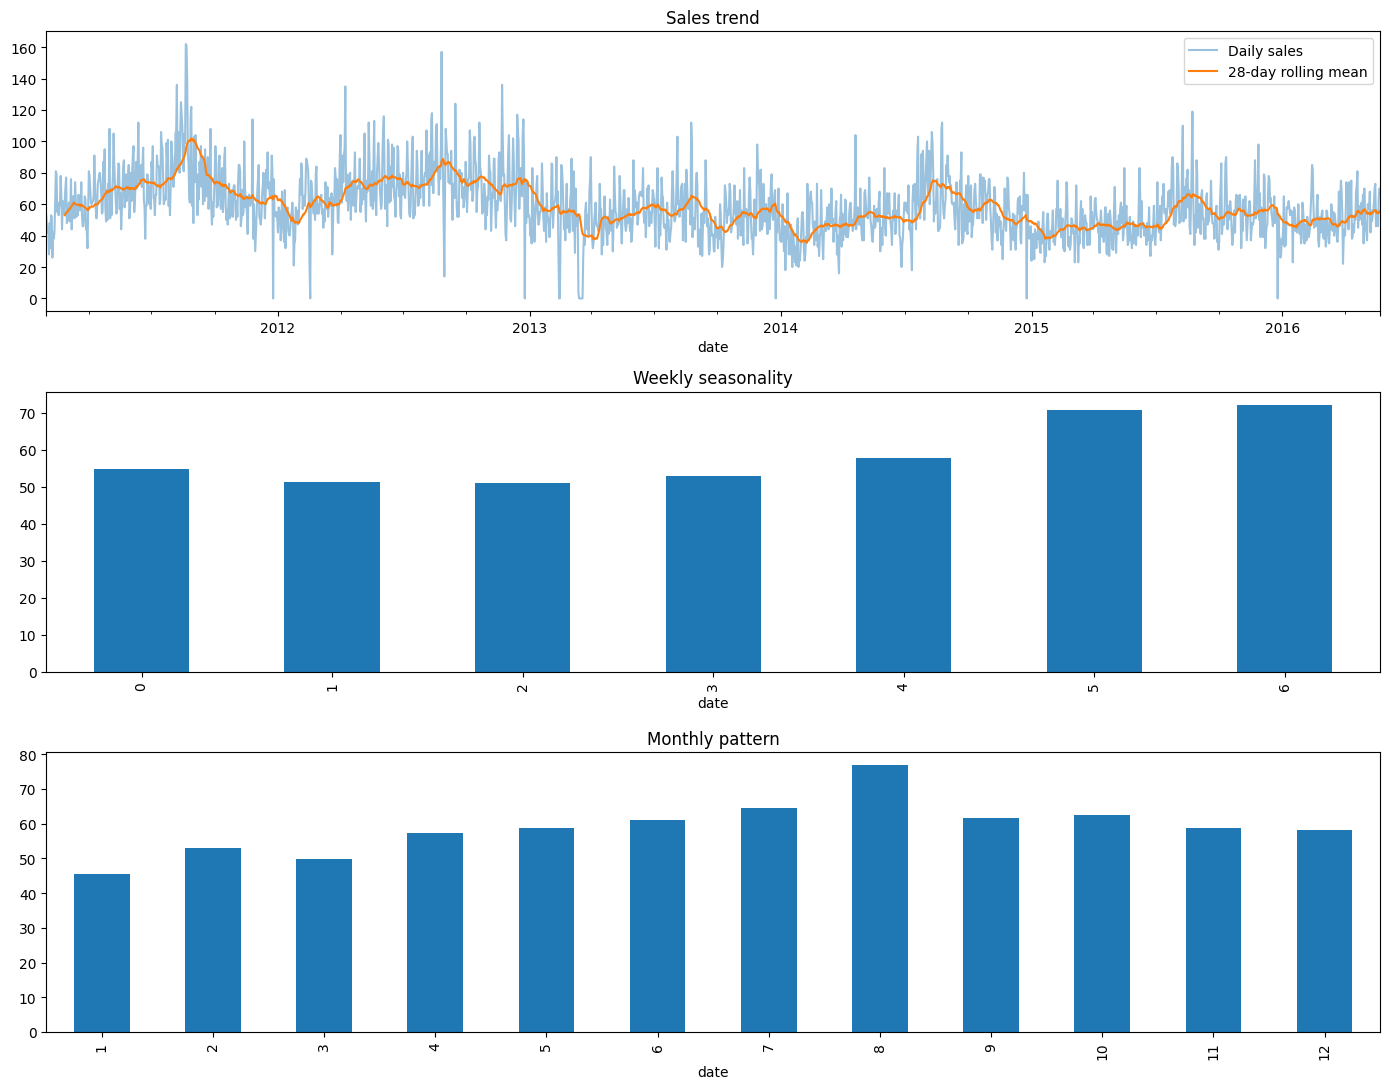

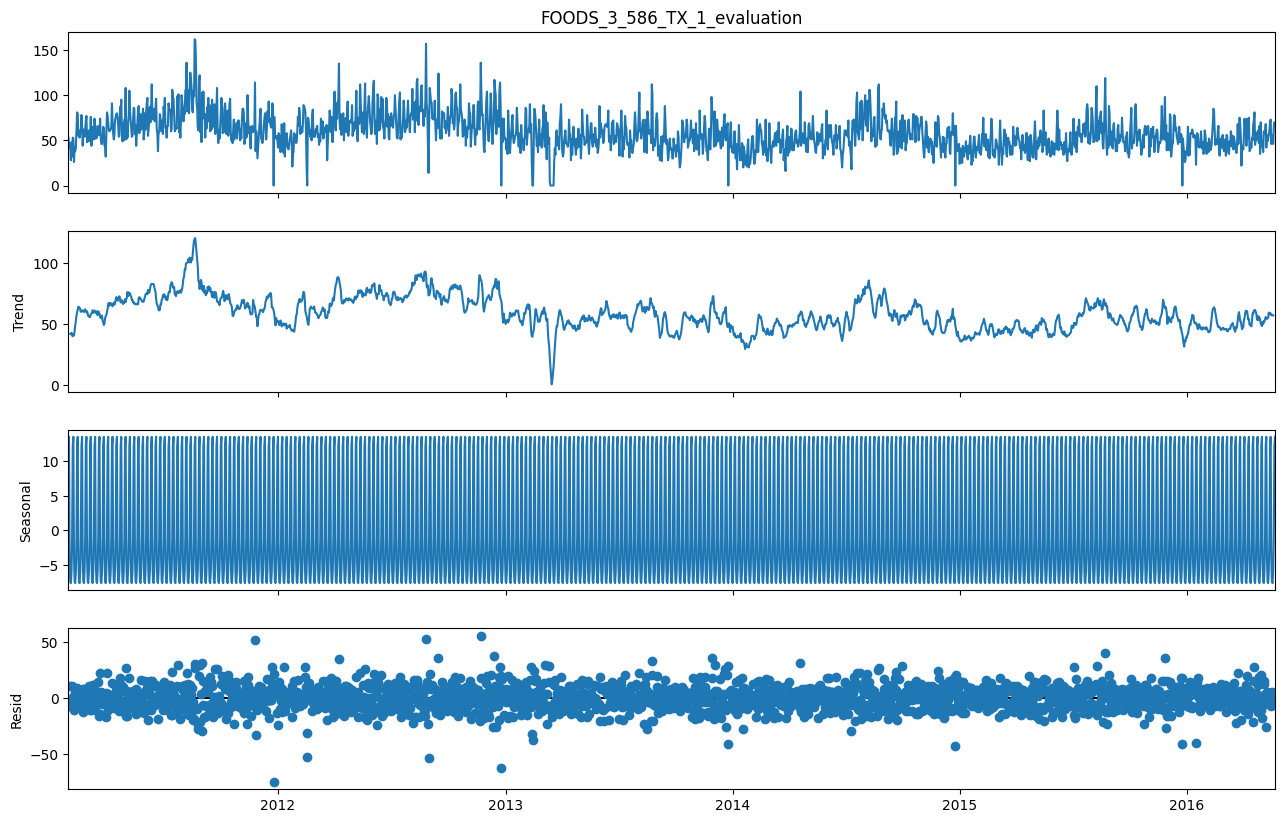

Raw sales: ADF=-3.531, p=0.00722 -> Stationary
First difference: ADF=-13.848, p=0.00000 -> Stationary
Normal average: 57.72016 Ramadan average: 69.36 Eid-window average: 65.18
These are descriptive associations, not causal effects or Pakistan-specific evidence.


In [ ]:
sample_id = SERIES_META.iloc[0].id
series = wide.loc[:LAST, sample_id].dropna()

fig, axes = plt.subplots(3,1,figsize=(14,11))
series.plot(ax=axes[0], alpha=.45, label="Daily sales")
series.rolling(28).mean().plot(ax=axes[0], label="28-day rolling mean")
axes[0].set_title("Sales trend"); axes[0].legend()
series.groupby(series.index.dayofweek).mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Weekly seasonality")
series.groupby(series.index.month).mean().plot(kind="bar", ax=axes[2])
axes[2].set_title("Monthly pattern")
plt.tight_layout(); plt.savefig(FIG_DIR/"eda_overview.png",dpi=120); plt.show()

decomp = seasonal_decompose(series, model="additive", period=7)
f = decomp.plot(); f.set_size_inches(14,9); f.savefig(FIG_DIR/"weekly_decomposition.png",dpi=120); plt.show()

def adf_report(x,label):
    stat,p,*_ = adfuller(x.dropna(),autolag="AIC")
    print(f"{label}: ADF={stat:.3f}, p={p:.5f} ->", "Stationary" if p<.05 else "Non-stationary")
adf_report(series,"Raw sales")
adf_report(series.diff(),"First difference")

ec = cal_idx.reindex(series.index)
normal = series[(ec.ramadan==0)&(ec.eid==0)].mean()
ram_avg = series[ec.ramadan==1].mean()
eid_avg = series[ec.eid==1].mean()
print("Normal average:",normal,"Ramadan average:",ram_avg,"Eid-window average:",eid_avg)


Forecast metrics and model functions

In [ ]:
def wape(y,p): return float(np.abs(y-p).sum()/max(np.abs(y).sum(),EPS)*100)
def mae(y,p): return float(np.mean(np.abs(y-p)))
def smape(y,p): return float(np.mean(2*np.abs(y-p)/np.maximum(np.abs(y)+np.abs(p),EPS))*100)
def mape_nonzero(y,p):
    m=y!=0
    return float(np.mean(np.abs((y[m]-p[m])/y[m]))*100) if m.any() else np.nan
def coverage(y,lo,hi): return float(np.mean((y>=lo)&(y<=hi))*100)

def pack(idx,p,lo,hi):
    p=np.maximum(np.asarray(p,dtype=float),0)
    lo=np.maximum(np.minimum(np.asarray(lo,dtype=float),p),0)
    hi=np.maximum(np.maximum(np.asarray(hi,dtype=float),p),0)
    return pd.DataFrame({"yhat":p,"lo":lo,"hi":hi},index=idx)

def naive_fc(train,future):
    sd=train.diff().dropna().std()
    if not np.isfinite(sd): sd=0
    h=np.arange(1,len(future)+1)
    p=np.repeat(float(train.iloc[-1]),len(future))
    band=1.2816*sd*np.sqrt(h)
    return pack(future,p,p-band,p+band)

def seasonal_naive_fc(train,future):

    step=np.arange(len(future))
    weeks_back=np.floor(step/7).astype(int)+1
    source=future-pd.to_timedelta(7*weeks_back,unit="D")
    p=train.reindex(source).to_numpy(dtype=float)
    p=np.where(np.isfinite(p),p,float(train.mean()))
    sd=(train-train.shift(7)).dropna().std()
    if not np.isfinite(sd): sd=0
    band=np.repeat(1.2816*sd,len(future))
    return pack(future,p,p-band,p+band)

def sarima_fc(train,future):
    ex_train=cal_idx.reindex(train.index)[["ramadan","eid"]].fillna(0).to_numpy(float)
    ex_future=cal_idx.reindex(future)[["ramadan","eid"]].fillna(0).to_numpy(float)
    model=SARIMAX(train.to_numpy(float),exog=ex_train,order=(1,0,1),
        seasonal_order=(1,0,0,7),enforce_stationarity=False,enforce_invertibility=False)
    fitted=model.fit(disp=False,maxiter=100)
    fc=fitted.get_forecast(steps=len(future),exog=ex_future)
    ci=np.asarray(fc.conf_int(alpha=.20))
    return pack(future,fc.predicted_mean,ci[:,0],ci[:,1])

def prophet_fc(train,future):
    df=pd.DataFrame({"ds":train.index,"y":train.to_numpy(float)})
    model=Prophet(weekly_seasonality=True,yearly_seasonality=True,
        daily_seasonality=False,holidays=HOLIDAYS_PROPHET,interval_width=.80)
    model.fit(df)
    pred=model.predict(pd.DataFrame({"ds":future}))
    return pack(future,pred.yhat,pred.yhat_lower,pred.yhat_upper)

FALLBACK_LOG=[]
def safe_stat(name,func,train,future):
    try: return func(train,future),name
    except Exception as e:
        FALLBACK_LOG.append({"model":name,"error":repr(e)})
        return seasonal_naive_fc(train,future),f"{name} [fallback: Seasonal Naive]"

print("Forecasting functions ready")

Forecasting functions ready


**LightGBM global model and quantile bounds**

In [ ]:
LGB_PARAMS=dict(n_estimators=300,learning_rate=.05,num_leaves=31,
    min_child_samples=20,subsample=.8,subsample_freq=1,
    colsample_bytree=.8,random_state=42,verbosity=-1)

def lgb_fc(origin,test_rows):
    tr=full[(full.date<origin)&(full.date>=origin-pd.Timedelta(days=TRAIN_WINDOW))&full.sales.notna()]
    if tr.empty: raise ValueError("Empty LightGBM training data")
    X,y=tr[FEATURES],tr.sales.astype(float)
    med=lgb.LGBMRegressor(objective="regression",**LGB_PARAMS).fit(X,y)
    low=lgb.LGBMRegressor(objective="quantile",alpha=.10,**LGB_PARAMS).fit(X,y)
    high=lgb.LGBMRegressor(objective="quantile",alpha=.90,**LGB_PARAMS).fit(X,y)
    out=test_rows[["id","date"]].copy()
    out["yhat"]=np.maximum(med.predict(test_rows[FEATURES]),0)
    out["lo"]=np.maximum(low.predict(test_rows[FEATURES]),0)
    out["hi"]=np.maximum(high.predict(test_rows[FEATURES]),0)
    out["lo"]=np.minimum(out.lo,out.yhat)
    out["hi"]=np.maximum(out.hi,out.yhat)
    return out

print("LightGBM ready")

LightGBM ready


**Walk-forward backtesting **



In [ ]:
ORIGINS=[LAST-pd.Timedelta(days=H*(N_FOLDS-i)-1) for i in range(N_FOLDS)]
print("Origins:",[d.date() for d in ORIGINS])
ids=SERIES_META.id.tolist()
blocks=[]

for fold,origin in enumerate(ORIGINS,1):
    future=pd.date_range(origin,periods=H,freq="D")
    test=full[full.date.isin(future)].copy()
    lgb_out=lgb_fc(origin,test)
    for sid in ids:
        s=wide[sid]
        train=s[(s.index<origin)&(s.index>=origin-pd.Timedelta(days=TRAIN_WINDOW))].dropna()
        actual=s.reindex(future).to_numpy(float)
        if len(train)<100 or not np.isfinite(actual).all():
            raise ValueError(f"Insufficient training/actual data: {sid}, {origin}")
        preds={
            "Naive":(naive_fc(train,future),"Naive"),
            "Seasonal Naive":(seasonal_naive_fc(train,future),"Seasonal Naive")
        }
        a,an=safe_stat("SARIMA",sarima_fc,train,future)
        b,bn=safe_stat("Prophet",prophet_fc,train,future)
        preds["SARIMA"]=(a,an); preds["Prophet"]=(b,bn)
        lp=lgb_out[lgb_out.id==sid].set_index("date").reindex(future)[["yhat","lo","hi"]]
        preds["LightGBM"]=(lp,"LightGBM")
        for pred,label in preds.values():
            z=pred.reset_index(drop=True).copy()
            z["model"]=label; z["fold"]=fold; z["origin"]=origin
            z["id"]=sid; z["date"]=future; z["actual"]=actual
            blocks.append(z[["model","fold","origin","id","date","actual","yhat","lo","hi"]])
    print("Completed fold",fold,"of",N_FOLDS)

backtest=pd.concat(blocks,ignore_index=True)
backtest=backtest.merge(SERIES_META[["id","store_id","cat_id","item_id"]],on="id",how="left")
backtest.to_csv(OUT_DIR/"backtest_predictions.csv",index=False)
print("Backtest rows:",len(backtest),"| model fallback events:",len(FALLBACK_LOG))
if FALLBACK_LOG: display(pd.DataFrame(FALLBACK_LOG).head(10))

Origins: [datetime.date(2016, 3, 28), datetime.date(2016, 4, 25)]
Completed fold 1 of 2
Completed fold 2 of 2
Backtest rows: 3360 | model fallback events: 0


**Model comparison, category/store error and chart**

In [ ]:
def metric_row(g):
    y=g.actual.to_numpy(); p=g.yhat.to_numpy()
    return pd.Series({"MAE":mae(y,p),"WAPE(%)":wape(y,p),
        "sMAPE(%)":smape(y,p),"MAPE_nonzero(%)":mape_nonzero(y,p),
        "PI coverage(%)":coverage(y,g.lo.to_numpy(),g.hi.to_numpy())})

comparison=pd.DataFrame([
    {"model":name, **metric_row(group).to_dict()}
    for name,group in backtest.groupby("model")
]).sort_values("WAPE(%)").reset_index(drop=True)
base=float(comparison.loc[comparison.model=="Seasonal Naive","WAPE(%)"].iloc[0])
real = comparison[~comparison.model.str.contains("fallback")]
BEST_MODEL = real.iloc[0].model
display(comparison.round(3))
print("Best evaluated model:",BEST_MODEL)

def group_error(col):
    rows=[]
    for (m,v),g in backtest.groupby(["model",col]):
        rows.append({"model":m,col:v,"WAPE(%)":wape(g.actual.to_numpy(),g.yhat.to_numpy())})
    return pd.DataFrame(rows).pivot(index="model",columns=col,values="WAPE(%)").round(2).reset_index()

category_error=group_error("cat_id")
store_error=group_error("store_id")
display(category_error)
display(store_error)

fig=px.bar(comparison,x="model",y="WAPE(%)",color="model",title="Walk-forward model comparison (lower WAPE is better)")
fig.write_html(FIG_DIR/"model_comparison.html")
fig.show()

,model,MAE,WAPE(%),sMAPE(%),MAPE_nonzero(%),PI coverage(%)
0,LightGBM,6.110,31.862,68.717,67.048,69.494
1,Prophet,6.585,34.342,69.864,69.346,79.911
2,SARIMA,7.482,39.019,72.841,71.659,84.524
3,Seasonal Naive,7.863,41.006,70.855,96.738,81.994
4,Naive,10.991,57.318,75.038,109.495,97.173


Best evaluated model: LightGBM


cat_id,model,FOODS,HOBBIES,HOUSEHOLD
0,LightGBM,21.03,98.32,50.97
1,Naive,47.02,124.37,73.11
2,Prophet,23.14,108.97,50.51
3,SARIMA,29.95,94.39,55.21
4,Seasonal Naive,28.54,109.93,67.67


store_id,model,CA_1,TX_1
0,LightGBM,31.12,32.76
1,Naive,66.06,46.78
2,Prophet,37.17,30.93
3,SARIMA,44.64,32.25
4,Seasonal Naive,39.59,42.71


**Final 28-day forecast and inventory order estimate**

In [ ]:
FINAL_ORIGIN=LAST+pd.Timedelta(days=1)
FINAL_DATES=pd.date_range(FINAL_ORIGIN,periods=H,freq="D")
if FINAL_DATES.max()>cal.date.max(): raise ValueError("Calendar lacks future dates for forecast.")
final_test=full[full.date.isin(FINAL_DATES)].copy()
final_lgb=lgb_fc(FINAL_ORIGIN,final_test)

final_blocks=[]
for sid in ids:
    s=wide[sid]
    train=s[(s.index<FINAL_ORIGIN)&(s.index>=FINAL_ORIGIN-pd.Timedelta(days=TRAIN_WINDOW))].dropna()
    preds={"Naive":(naive_fc(train,FINAL_DATES),"Naive"),
           "Seasonal Naive":(seasonal_naive_fc(train,FINAL_DATES),"Seasonal Naive")}
    a,an=safe_stat("SARIMA",sarima_fc,train,FINAL_DATES)
    b,bn=safe_stat("Prophet",prophet_fc,train,FINAL_DATES)
    preds["SARIMA"]=(a,an); preds["Prophet"]=(b,bn)
    lp=final_lgb[final_lgb.id==sid].set_index("date").reindex(FINAL_DATES)[["yhat","lo","hi"]]
    preds["LightGBM"]=(lp,"LightGBM")
    for pred,label in preds.values():
        z=pred.reset_index(drop=True).copy()
        z["model"]=label; z["id"]=sid; z["date"]=FINAL_DATES
        final_blocks.append(z[["model","id","date","yhat","lo","hi"]])

forecasts=pd.concat(final_blocks,ignore_index=True)
history=full.loc[full.sales.notna(),["id","store_id","cat_id","item_id","date","sales"]].copy()

def aggregate_uncertainty(f,z=1.2816):
    demand=float(f.yhat.sum())
    sigma=np.maximum((f.hi.to_numpy()-f.lo.to_numpy())/(2*1.2816),0)
    total_sigma=float(np.sqrt(np.sum(sigma**2)))
    return demand,max(0,demand-z*total_sigma),demand+z*total_sigma,total_sigma

def order_plan(model,sid,current_stock=0,z=1.2816):
    f=forecasts[(forecasts.model==model)&(forecasts.id==sid)].sort_values("date")
    demand,low,high,sigma=aggregate_uncertainty(f,z)
    safety=z*sigma
    return {"model":model,"id":sid,"expected_demand_28d":round(demand,1),
            "approx_80pct_lower":round(low,1),"approx_80pct_upper":round(high,1),
            "safety_stock_approx":round(safety,1),"current_stock":current_stock,
            "suggested_order":round(max(0,demand+safety-current_stock),1)}

available_final_models=set(forecasts.model.unique())
BEST_MODEL=next((m for m in comparison.model if m in available_final_models), None)
if BEST_MODEL is None: raise ValueError("No backtested model has a matching final forecast.")
example_id=SERIES_META.iloc[0].id
display(pd.DataFrame([order_plan(BEST_MODEL,example_id,current_stock=50)]))

hh=history[history.id==example_id].sort_values("date").tail(120)
ff=forecasts[(forecasts.id==example_id)&(forecasts.model==BEST_MODEL)].sort_values("date")
fig=go.Figure()
fig.add_trace(go.Scatter(x=hh.date,y=hh.sales,name="History"))
fig.add_trace(go.Scatter(x=ff.date,y=ff.hi,line=dict(width=0),showlegend=False))
fig.add_trace(go.Scatter(x=ff.date,y=ff.lo,fill="tonexty",fillcolor="rgba(0,120,255,.18)",line=dict(width=0),name="Daily 80% interval"))
fig.add_trace(go.Scatter(x=ff.date,y=ff.yhat,name="Forecast"))
fig.update_layout(title=f"{example_id} — {BEST_MODEL} forecast",height=450,hovermode="x unified")
fig.write_html(FIG_DIR/"final_forecast_example.html")
fig.show()
print("Forecast:",FINAL_DATES.min().date(),"to",FINAL_DATES.max().date())

,model,id,expected_demand_28d,approx_80pct_lower,approx_80pct_upper,safety_stock_approx,current_stock,suggested_order
0,LightGBM,FOODS_3_586_TX_1_evaluation,1526.7,1461.4,1591.9,65.2,50,1541.9


Forecast: 2016-05-23 to 2016-06-19
